# 03 — Formulación y validación de hipótesis

Fases 2 y 6 del proyecto. Aquí planteamos las hipótesis con su H0 y H1, las justificamos desde el negocio y las validamos con pruebas estadísticas usando el valor p para tomar decisiones.

## 1. Formulación de hipótesis

En esta parte planteamos las hipótesis que vamos a validar. Las pensamos desde el lugar de una productora con un capital limitado que tiene que decidir en qué películas meterlo. En el notebook 01 partimos esa decisión en tres preguntas clave:

1. **¿Cuánto invertir?** Si meterle más presupuesto a una película hace que rinda más.
2. **¿Cuándo estrenar?** Si la fecha de estreno cambia el retorno.
3. **¿Qué tipo de película hacer?** Si el género influye en que la película dé plata.

De cada pregunta sale una hipótesis, y para cada una escogimos una de las pruebas de las guías del curso: correlación (semana 4), t de Student y chi-cuadrado (semana 6). Antes de plantear cada hipótesis miramos los datos para ver si hay un patrón que valga la pena probar.

Aquí **todavía no corremos las pruebas**, solo las planteamos. Para explorar usamos los datos limpios y las variables que dejamos listas en el notebook 02.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import seaborn as sns

sns.set_theme(style="whitegrid")

PROCESSED = Path("../data/processed")

UMBRAL_RENTABLE = 2
MESES_TEMPORADA_ALTA = [5, 6, 7, 8, 11, 12]

MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
AZUL, GRIS = "#2b6cb0", "#a0aec0"
FORMATO_MILLONES = FuncFormatter(lambda valor, _: f"{valor / 1e6:g}")

### 1.1 Datos para la exploración

Partimos de `peliculas_variables.csv`, el archivo que dejamos en el notebook 02 con los datos limpios y las variables derivadas, y nos quedamos con las películas de la base financiera (`base_financiera`):

- Ya estrenadas (`status = Released`).
- Con presupuesto y recaudación reportados. Los ceros de `budget` y `revenue` eran datos que nadie reportó, y en la limpieza quedaron como faltantes.
- Sin montos menores a 10.000 dólares (`monto_dudoso`). Hay presupuestos de 1, 7 o 25 dólares que están mal digitados, y como el retorno se calcula dividiendo por el presupuesto, una sola de esas filas da retornos absurdos.

In [2]:
peliculas = pd.read_csv(PROCESSED / "peliculas_variables.csv", parse_dates=["release_date"],
                        dtype={"anio": "Int64", "mes": "Int64",
                               "temporada_alta": "boolean", "rentable": "boolean"})
finanzas = peliculas[peliculas["base_financiera"]].copy()

reportadas = peliculas["estrenada"] & peliculas["budget"].notna() & peliculas["revenue"].notna()
print(f"Estrenadas con presupuesto y recaudación: {reportadas.sum():,}")
print(f"De esas, con algún monto menor a 10.000 USD: {(reportadas & peliculas['monto_dudoso']).sum()}")
print(f"Películas para la exploración: {len(finanzas):,}")

Estrenadas con presupuesto y recaudación: 3,228
De esas, con algún monto menor a 10.000 USD: 24
Películas para la exploración: 3,204


**¿Qué vemos?** Los 24 casos que quedan por fuera los revisamos uno por uno en el diagnóstico del notebook 02 (sección 1.7). La mayoría son errores evidentes: *Angela's Ashes* aparece con 25 dólares de presupuesto y *Death at a Funeral* con 46 dólares de recaudación, cuando seguramente eran millones. Otros sí pueden ser reales. *Primer* (7.000 dólares) y *Tarnation* (218) son conocidas justamente por lo baratas, pero recaudaron 60 y más de 5.000 veces su presupuesto, y esos multiplicadores se comerían cualquier promedio. Y casos como *The Adventurer* (25 millones de presupuesto y 6.399 dólares de recaudación) pueden ser fracasos de verdad con un estreno muy limitado. Al sacarlas perdemos unos pocos fracasos reales, pero son 24 de 3.228 películas, menos del 1 %, así que el panorama no cambia.

Las tres hipótesis usan dos variables que creamos en el notebook 02 (sección 3.2):

- **Multiplicador** = `revenue / budget`: cuántas veces recuperó la película lo que costó. Es lo mismo que ROI + 1, pero se lee más fácil ("recaudó 2,5 veces su presupuesto"). Tiene otra ventaja: como el presupuesto y la recaudación están en dólares del mismo año, la inflación casi no lo afecta.
- **Rentable**: si el multiplicador es 2 o más. No basta con recaudar lo mismo que costó, porque de la taquilla una buena parte se la quedan las salas y los distribuidores, y el presupuesto que se reporta normalmente no incluye la publicidad. Recaudar el doble del presupuesto es una regla aproximada que se usa mucho en análisis de taquilla para estimar el punto de equilibrio (no sale de las guías del curso).

In [3]:
assert finanzas["rentable"].eq(finanzas["multiplicador"].ge(UMBRAL_RENTABLE)).all()

print(f"Rentables (multiplicador >= {UMBRAL_RENTABLE}):  {finanzas['rentable'].mean():.1%}")
print(f"Recaudaron más de lo que costaron: {(finanzas['multiplicador'] > 1).mean():.1%}")

Rentables (multiplicador >= 2):  56.2%
Recaudaron más de lo que costaron: 75.8%


Con el criterio de 2x, un poco más de la mitad de las películas son rentables; si solo pidiéramos recaudar más de lo que costaron, serían tres de cada cuatro. La diferencia es grande, y por eso dejamos explícito qué estamos llamando "rentable": cambiar el umbral cambia los resultados.

Hay que tener presente que esta base no es una muestra al azar. Son las películas que sí reportaron cifras, que tienden a ser las más comerciales. Eso afecta a las tres hipótesis y lo retomamos en las limitaciones.

Para comparar grupos en las tres hipótesis usamos siempre el mismo resumen:

In [4]:
def resumir(datos, por):
    tabla = datos.groupby(por, observed=True).agg(
        peliculas=("multiplicador", "size"),
        presupuesto_mediano=("budget", "median"),
        multiplicador_mediano=("multiplicador", "median"),
        rentables=("rentable", "mean"),
    )
    tabla["presupuesto_mediano"] /= 1e6
    tabla["rentables"] *= 100
    return tabla.round(1).rename(columns={
        "peliculas": "Películas",
        "presupuesto_mediano": "Presupuesto mediano (M USD)",
        "multiplicador_mediano": "Multiplicador mediano",
        "rentables": "% rentables",
    })

Usamos medianas y no promedios porque el multiplicador está muy sesgado a la derecha: unas pocas películas que recaudaron 50 o 100 veces su presupuesto subirían el promedio de cualquier grupo.

### 1.2 Criterios para las tres pruebas

- **Nivel de significancia α = 0,05.** Es el valor estándar, y aquí un error tipo I no es tan grave como en medicina: lo peor que pasa es que la productora cambie su estrategia por un efecto que no existe. Las consecuencias de cada tipo de error las resumimos al final.
- **Pruebas bilaterales.** En los tres casos el efecto podría ir para cualquier lado (lo explicamos en cada hipótesis), así que no nos amarramos a una dirección antes de correr la prueba.
- **El valor p no es suficiente.** Con más de 3.000 películas, casi cualquier diferencia sale significativa. Por eso, además del valor p, vamos a reportar qué tan grande es el efecto y si esa magnitud le importa al negocio.
- **No "aceptamos" H0.** Si el valor p es mayor que α, decimos que no hay evidencia suficiente para rechazarla.

### 1.3 Hipótesis 1: presupuesto y rentabilidad

**Pregunta de negocio:** ¿meterle más plata a una película hace que rinda más?

Que una película más cara recaude más es casi obvio: tiene más estrellas, más efectos y más publicidad. Pero a una productora con capital limitado no le interesa solo cuánto entra, sino cuánto rinde cada dólar que invierte. Por eso cruzamos el presupuesto con el multiplicador y no con la recaudación.

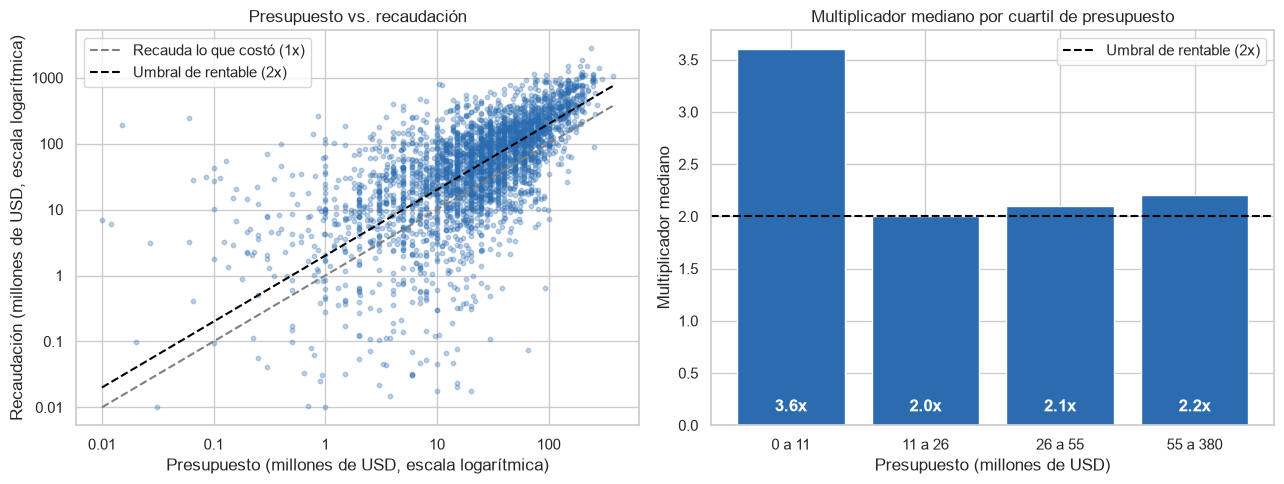

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
Presupuesto (M USD),,,,
0 a 11,826,5.0,3.6,65.6
11 a 26,776,18.0,2.0,51.2
26 a 55,817,38.0,2.1,51.5
55 a 380,785,85.0,2.2,56.2


In [5]:
cortes = finanzas["budget"].quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy()
etiquetas = [f"{inicio / 1e6:.0f} a {fin / 1e6:.0f}" for inicio, fin in zip(cortes[:-1], cortes[1:])]
cuartil_presupuesto = pd.cut(finanzas["budget"], cortes, labels=etiquetas, include_lowest=True)
por_cuartil = resumir(finanzas, cuartil_presupuesto).rename_axis("Presupuesto (M USD)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(finanzas["budget"], finanzas["revenue"], s=10, alpha=0.3, color=AZUL)
extremos = [finanzas["budget"].min(), finanzas["budget"].max()]
ax1.plot(extremos, extremos, color="gray", linestyle="--", linewidth=1.5,
         label="Recauda lo que costó (1x)")
ax1.plot(extremos, [UMBRAL_RENTABLE * x for x in extremos], color="black", linestyle="--",
         linewidth=1.5, label=f"Umbral de rentable ({UMBRAL_RENTABLE}x)")
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.xaxis.set_major_formatter(FORMATO_MILLONES)
ax1.yaxis.set_major_formatter(FORMATO_MILLONES)
ax1.set_title("Presupuesto vs. recaudación")
ax1.set_xlabel("Presupuesto (millones de USD, escala logarítmica)")
ax1.set_ylabel("Recaudación (millones de USD, escala logarítmica)")
ax1.legend(loc="upper left")

ax2.bar(por_cuartil.index, por_cuartil["Multiplicador mediano"], color=AZUL)
ax2.axhline(UMBRAL_RENTABLE, color="black", linestyle="--", linewidth=1.5,
            label=f"Umbral de rentable ({UMBRAL_RENTABLE}x)")
for i, valor in enumerate(por_cuartil["Multiplicador mediano"]):
    ax2.text(i, 0.1, f"{valor:.1f}x", ha="center", va="bottom", color="white", fontweight="bold")
ax2.set_title("Multiplicador mediano por cuartil de presupuesto")
ax2.set_xlabel("Presupuesto (millones de USD)")
ax2.set_ylabel("Multiplicador mediano")
ax2.legend()

plt.tight_layout()
plt.show()

por_cuartil

**¿Qué vemos?** A la izquierda, la recaudación sí sube con el presupuesto: la nube va en diagonal. De 10 millones para arriba va casi paralela a las líneas de 1x y 2x, o sea que las películas más caras no se alejan más del umbral que las de presupuesto medio. Por debajo de 10 millones la nube se abre mucho: hay películas que recaudaron cien veces o más lo que costaron y otras que casi no recaudaron nada, así que hacer cine barato también es más incierto. A la derecha se ve mejor: el cuarto de películas más baratas (hasta 11 millones) tiene un multiplicador mediano de 3,6 y el 66 % son rentables, mientras que en los otros tres cuartiles el multiplicador se queda alrededor de 2 y los rentables entre 51 % y 56 %. Si hay relación, sería negativa y no lineal: el cambio está entre las películas baratas y el resto.

Antes de plantear la hipótesis revisamos algo que nos hizo dudar. El presupuesto está en dólares de cada año, sin ajustar por inflación, y las películas viejas del dataset tienen presupuestos nominales muy bajos. Si además son sobre todo clásicos exitosos, quedarían todas en el cuartil barato con multiplicadores altos:

In [6]:
periodo = pd.cut(finanzas["anio"], [1900, 1979, 1989, 1999, 2009, 2017],
                 labels=["Antes de 1980", "1980-1989", "1990-1999", "2000-2009", "2010-2017"])
resumir(finanzas, periodo).rename_axis("Periodo de estreno")

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
Periodo de estreno,,,,
Antes de 1980,200,3.0,5.5,84.0
1980-1989,204,13.9,4.0,70.1
1990-1999,535,30.0,2.1,53.1
2000-2009,1324,30.0,2.0,49.7
2010-2017,941,30.0,2.4,58.2


**¿Qué vemos?** Se confirma la duda. Las películas de antes de 1980 tienen un presupuesto mediano de 3 millones y las de los 80 de 14, contra 30 millones desde los 90. Al mismo tiempo, sus multiplicadores medianos son de 5,5 y 4,0, con 84 % y 70 % de rentables, mientras que desde los 90 el multiplicador ronda 2. Esas películas viejas no llegaron al dataset por azar: es mucho más probable que TMDB tenga las cifras de un clásico que de una película de 1975 que nadie recuerda. Entonces parte de la ventaja del cuartil barato puede ser un efecto de la época y no del presupuesto.

Por eso la prueba se corre dos veces: sobre toda la base y solo con las películas desde 2000, donde los presupuestos son comparables entre sí. Otra opción sería ajustar los montos por inflación, pero eso no está en las guías y tampoco resolvería el sesgo de los clásicos.

**Hipótesis 1**

- **H0:** no hay correlación entre el presupuesto y el multiplicador (ρ = 0).
- **H1:** sí hay correlación entre el presupuesto y el multiplicador (ρ ≠ 0).

**Variables:** `budget` (cuantitativa continua) y `multiplicador` (cuantitativa continua, derivada de `revenue / budget`). Para el control por época, el año de estreno (`anio`).

**Prueba prevista:** correlación de Spearman con su prueba de significancia. No usamos Pearson por lo que vimos en la guía de la semana 4: Pearson solo mide relaciones lineales y es sensible a los valores extremos, y aquí tenemos un multiplicador muy sesgado y una relación que, si existe, no es lineal. Spearman trabaja con los rangos, así que además da lo mismo usar el multiplicador o el ROI. Es bilateral porque la relación podría ir para los dos lados: más presupuesto puede traer estrellas y publicidad que suben el retorno, o puede tener rendimientos decrecientes.

**Supuestos a verificar:**

- Que la relación sea monótona, lo que revisamos con la gráfica de dispersión sobre los datos limpios.
- Que las observaciones sean independientes: cada película aparece una sola vez.
- Que los montos estén bien limpios. Como el multiplicador divide por el presupuesto, un presupuesto mal digitado (muy bajo) infla el multiplicador y crea una correlación negativa artificial.

**Qué haríamos con el resultado:**

- Si se rechaza H0 con ρ negativo y se mantiene desde 2000, la productora no debería asumir que más presupuesto es mejor negocio, y tendría sentido repartir el capital en varias películas de menor presupuesto en vez de apostarlo todo a una grande.
- Si se rechaza con ρ positivo, las producciones grandes además de recaudar más rinden más por dólar, y concentrar la inversión tendría respaldo.
- Si no se rechaza, o si la correlación desaparece desde 2000, el presupuesto por sí solo no dice nada del retorno, y la decisión de cuánto invertir se tendría que apoyar en otras variables, como las de las hipótesis 2 y 3.

**Lo que no va a poder decir:** aunque salga una correlación, no prueba que bajar el presupuesto suba el retorno. Las películas baratas y las caras se diferencian en muchas otras cosas (género, productora, distribución). Y en las baratas es donde más pesa el sesgo de selección: una película pequeña que fracasó tiene menos probabilidad de reportar su taquilla que un *blockbuster* que fracasó.

### 1.4 Hipótesis 2: temporada de estreno

**Pregunta de negocio:** ¿estrenar en temporada alta mejora el retorno?

La fecha de estreno es de las pocas decisiones que la productora o la distribuidora todavía puede tomar cuando la película ya está hecha. Casi el 94 % de las películas del dataset son en inglés (notebook 01), es decir, cine pensado sobre todo para el mercado de Estados Unidos, así que definimos la temporada alta con el calendario de allá:

- **Verano:** de mayo a agosto, cuando los estudiantes están de vacaciones.
- **Fin de año:** noviembre y diciembre (Acción de Gracias y Navidad).

La definimos por calendario y no escogiendo los meses que mejor salen en la gráfica: agosto, por ejemplo, queda en temporada alta aunque su multiplicador no está entre los más altos. Si escogiéramos los meses según el resultado, la prueba quedaría amañada.

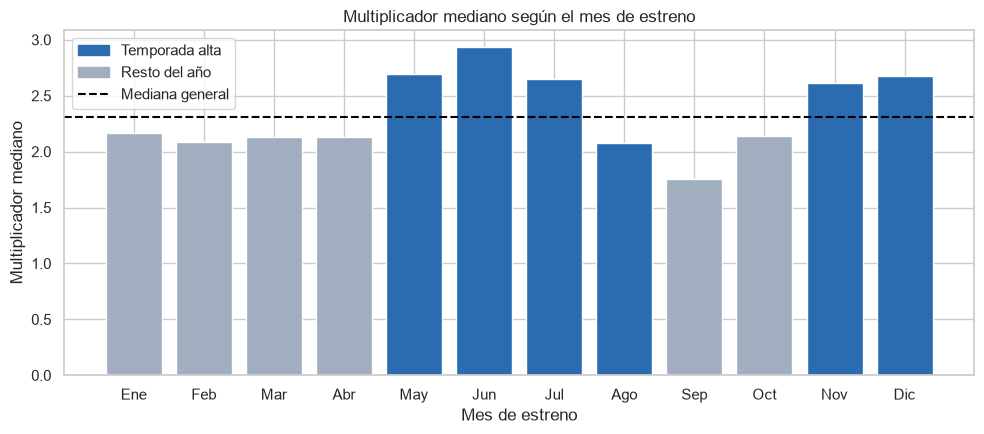

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
temporada,,,,
Resto del año,1540,21.0,2.0,50.6
Temporada alta,1664,31.0,2.6,61.4


In [7]:
assert finanzas["temporada_alta"].eq(finanzas["mes"].isin(MESES_TEMPORADA_ALTA)).all()
finanzas["temporada"] = finanzas["temporada_alta"].map({True: "Temporada alta", False: "Resto del año"})

mediana_por_mes = finanzas.groupby("mes")["multiplicador"].median()
colores = [AZUL if mes in MESES_TEMPORADA_ALTA else GRIS for mes in mediana_por_mes.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar([MESES[mes - 1] for mes in mediana_por_mes.index], mediana_por_mes, color=colores)
ax.axhline(finanzas["multiplicador"].median(), color="black", linestyle="--", linewidth=1.5)
ax.legend(handles=[Patch(color=AZUL, label="Temporada alta"),
                   Patch(color=GRIS, label="Resto del año"),
                   Line2D([], [], color="black", linestyle="--", label="Mediana general")])
ax.set_title("Multiplicador mediano según el mes de estreno")
ax.set_xlabel("Mes de estreno")
ax.set_ylabel("Multiplicador mediano")
plt.tight_layout()
plt.show()

resumir(finanzas, "temporada")

**¿Qué vemos?** Cinco de los seis meses de temporada alta quedan por encima de la mediana general; la excepción es agosto. Junio es el mejor mes y septiembre el peor. En la tabla, las películas de temporada alta tienen un multiplicador mediano de 2,6 contra 2,0 del resto del año, y el 61 % son rentables contra el 51 %.

Pero la tabla también muestra un problema: en temporada alta se estrenan las películas más caras (presupuesto mediano de 31 millones contra 21). Si comparáramos la recaudación, buena parte de la diferencia se explicaría solo por eso. Por eso la prueba usa el multiplicador, que ya está dividido por el presupuesto. Aun así no lo controla todo: en esas fechas también salen las secuelas y las películas con más publicidad.

**Hipótesis 2**

- **H0:** el promedio del logaritmo del multiplicador es igual para las películas estrenadas en temporada alta y para las del resto del año (μ_alta = μ_resto).
- **H1:** el promedio del logaritmo del multiplicador es diferente entre los dos grupos (μ_alta ≠ μ_resto).

**Variables:** `temporada_alta` (cualitativa nominal binaria, derivada del mes de estreno en el notebook 02) y `log10(multiplicador)` (cuantitativa continua).

**Prueba prevista:** t de Student para dos muestras independientes, en la versión de Welch, que no asume que los dos grupos tienen la misma varianza. La t de Student está en la guía de la semana 6; la versión de Welch no, así que la consultamos aparte. Usamos el logaritmo porque la t compara promedios y, como dijimos, el multiplicador sin transformar tiene una cola muy larga. Al final devolvemos la diferencia a la escala original para decirla en términos de negocio (cuántas veces más rinde una película en temporada alta). Es bilateral porque la temporada alta también tiene más competencia: hay más estrenos peleándose por las mismas salas, y eso podría bajar el retorno en vez de subirlo.

**Supuestos a verificar:**

- Normalidad aproximada del logaritmo del multiplicador en cada grupo, con histograma y gráfico Q-Q. Como cada grupo tiene más de 1.500 películas, el teorema del límite central nos da margen si no es perfectamente normal.
- Independencia: cada película está en un solo grupo.
- Varianzas de los grupos: las comparamos para justificar el uso de Welch.

**Qué haríamos con el resultado:**

- Si se rechaza H0 y la temporada alta rinde más, vale la pena pelear por esas fechas, aunque conseguirlas cueste más.
- Si se rechaza y rinde menos, la competencia pesa más que el público extra, y estrenar fuera de temporada sería una estrategia válida.
- Si no se rechaza, la fecha por sí sola no cambia el retorno y se puede escoger por otros criterios, como evitar la competencia directa.

**Lo que no va a poder decir:** que mover una película a julio la vuelva más rentable. Los estudios reservan esas fechas para las películas en las que más confían, entonces el grupo de temporada alta ya viene escogido. Además, en TMDB `release_date` suele ser el primer estreno registrado, que puede ser un festival o el estreno en otro país, no necesariamente el estreno comercial en Estados Unidos.

### 1.5 Hipótesis 3: género y rentabilidad

**Pregunta de negocio:** ¿el género de la película influye en que sea rentable?

El género es de las primeras decisiones de un proyecto: define el guion, el reparto y el público. Si unos géneros tienen más probabilidad de ser rentables que otros, eso ayuda a escoger qué producir.

Usamos el **género principal** (el primero que lista TMDB) y no todos los géneros, porque la chi-cuadrado necesita que cada película se cuente una sola vez; con todos los géneros, una película de acción y aventura aparecería en dos filas de la tabla. Los géneros con menos de 50 películas los juntamos en "Otros": con tan pocas, cada película mueve el porcentaje de rentables 2 puntos o más y la comparación no es confiable. Esa agrupación quedó en la columna `genero_agrupado` del notebook 02.

Películas sin género registrado: 1
Géneros agrupados en 'Otros': Family, Documentary, Mystery, Western, Music, History, War, Foreign


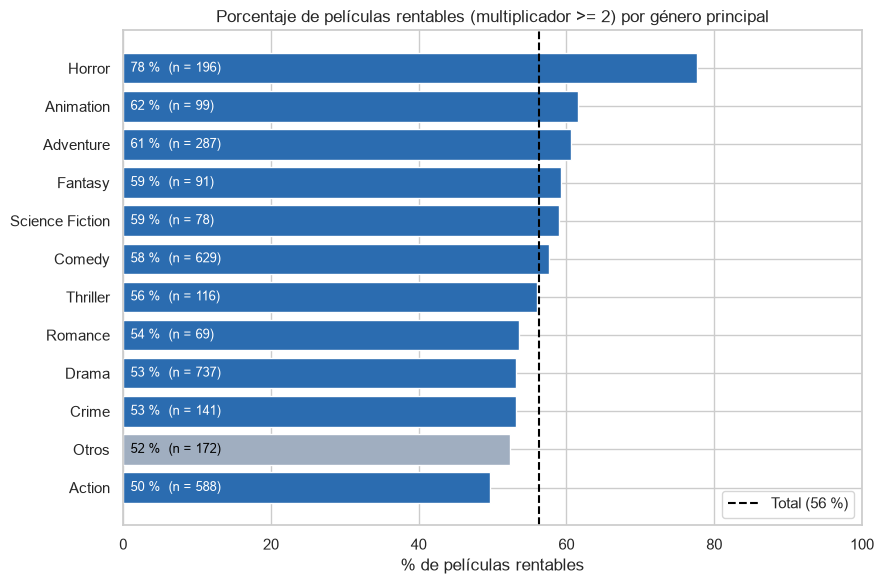

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
genero_agrupado,,,,
Horror,196,10.9,3.7,77.6
Animation,99,76.0,2.6,61.6
Adventure,287,60.0,2.7,60.6
Fantasy,91,50.0,2.4,59.3
Science Fiction,78,35.5,2.8,59.0
Comedy,629,20.0,2.5,57.7
Thriller,116,27.0,2.2,56.0
Romance,69,23.0,2.5,53.6
Crime,141,20.0,2.1,53.2


In [8]:
print(f"Películas sin género registrado: {finanzas['genero_agrupado'].isna().sum()}")

con_genero = finanzas.dropna(subset=["genero_agrupado"])
generos_en_otros = con_genero.loc[con_genero["genero_agrupado"] == "Otros", "genero_principal"].value_counts()
print(f"Géneros agrupados en 'Otros': {', '.join(generos_en_otros.index)}")

por_genero = resumir(con_genero, "genero_agrupado").sort_values("% rentables")
porcentaje_total = con_genero["rentable"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 6))
colores = [GRIS if genero == "Otros" else AZUL for genero in por_genero.index]
ax.barh(por_genero.index, por_genero["% rentables"], color=colores)
ax.axvline(porcentaje_total, color="black", linestyle="--", linewidth=1.5,
           label=f"Total ({porcentaje_total:.0f} %)")
barras = zip(por_genero["% rentables"], por_genero["Películas"], colores)
for i, (porcentaje, cantidad, color) in enumerate(barras):
    ax.text(1, i, f"{porcentaje:.0f} %  (n = {cantidad})", va="center", fontsize=9,
            color="white" if color == AZUL else "black")
ax.set_xlim(0, 100)
ax.set_title(f"Porcentaje de películas rentables (multiplicador >= {UMBRAL_RENTABLE}) por género principal")
ax.set_xlabel("% de películas rentables")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

por_genero.sort_values("% rentables", ascending=False)

**¿Qué vemos?** Hay diferencias grandes entre géneros. Terror (*Horror*) es el que más se sale: el 78 % de sus películas son rentables, contra el 56 % del total. En el otro extremo está acción (*Action*), con menos de la mitad. La mayoría de géneros queda entre 53 % y 62 %, cerca del total.

La tabla deja ver algo que hay que tener en cuenta: terror tiene el presupuesto mediano más bajo de los géneros grandes (11 millones, contra 44 de acción). Eso lo conecta con la hipótesis 1, porque puede que no sea el género sino el presupuesto lo que hace la diferencia, o las dos cosas. La chi-cuadrado no separa esos dos efectos, así que hay que tenerlo presente al interpretar.

**Hipótesis 3**

- **H0:** el género principal y ser rentable son independientes, es decir, la proporción de películas rentables es la misma en todos los géneros.
- **H1:** el género principal y ser rentable están asociados: al menos un género tiene una proporción de rentables distinta.

**Variables:** `genero_agrupado` (cualitativa nominal: el género principal, con los de menos de 50 películas en "Otros") y `rentable` (cualitativa nominal binaria, derivada del multiplicador).

**Prueba prevista:** chi-cuadrado de independencia sobre la tabla de contingencia género × rentable (12 × 2), que es la prueba de la guía de la semana 6 para dos variables categóricas. La chi-cuadrado no tiene dirección: si sale significativa, solo dice que hay asociación y no cuáles géneros la producen, así que después comparamos las frecuencias observadas con las esperadas para ver qué géneros se alejan más. Para medir qué tan fuerte es la asociación pensamos usar la V de Cramér, que no está en las guías y la tendríamos que consultar aparte.

**Supuestos a verificar:**

- Frecuencias esperadas mayores que 5 en todas las celdas. El grupo más pequeño tiene 69 películas y un 44 % de no rentables en total, así que la esperada más baja debería quedar alrededor de 30; no esperamos problemas, pero hay que confirmarlo.
- Independencia: cada película se cuenta una sola vez, que es la razón para usar el género principal.

**Qué haríamos con el resultado:**

- Si se rechaza H0, el género sí pesa en la probabilidad de recuperar la inversión, y la productora puede darles prioridad a los géneros que queden por encima de lo esperado, mirando también el presupuesto típico de cada uno.
- Si no se rechaza, no hay evidencia de que algún género sea más seguro que otro, y el género se puede escoger por otros criterios (público objetivo, costo, talento disponible).

**Lo que no va a poder decir:** que hacer una película de terror garantice que sea rentable, ni que el género sea la causa. Además, el primer género de TMDB no siempre es el que mejor describe la película: una comedia romántica puede aparecer primero como *Romance* o como *Comedy*.

### 1.6 Resumen de las hipótesis

| | Pregunta de negocio | Variables | Prueba prevista | Supuesto más delicado |
|---|---|---|---|---|
| **H1** | ¿Más presupuesto rinde más por dólar? | `budget`, `multiplicador` | Correlación de Spearman (toda la base y desde 2000) | Montos bien limpios y control por época |
| **H2** | ¿Estrenar en temporada alta rinde más? | `temporada_alta`, `log10(multiplicador)` | t de Student para muestras independientes (Welch) | Normalidad aproximada del logaritmo |
| **H3** | ¿El género influye en que una película sea rentable? | `genero_agrupado`, `rentable` | Chi-cuadrado de independencia | Frecuencias esperadas mayores que 5 |

Y lo que le costaría a la productora equivocarse en cada caso:

| | Error tipo I (rechazar H0 siendo cierta) | Error tipo II (no rechazar H0 siendo falsa) |
|---|---|---|
| **H1** | Recorta presupuestos creyendo que así rinden más, y pierde alcance sin ganar retorno. | Sigue invirtiendo igual sin aprovechar una diferencia real de rendimiento. |
| **H2** | Paga más por fechas de temporada alta que en realidad no mejoran el retorno. | Estrena en cualquier fecha y desaprovecha una temporada que sí rinde más. |
| **H3** | Se casa con un género que en realidad no es más seguro que los demás. | Ignora un género con más probabilidad de ser rentable. |

Las tres hipótesis comparten las mismas limitaciones de base: solo cubren las películas que reportaron presupuesto y recaudación, ninguna prueba demuestra causalidad y la definición de rentable es una aproximación. Las pruebas las corremos en la siguiente parte de este notebook.